# The 97 published blasts and the ten campaigns they come from

**Question:** Which campaigns does the corpus hold, and how unequal are they?

**Level 1: Fundamentals** · Needs: nothing, this is the entry notebook · Reading time: about 20 minutes

## Objectives

Fragmenta predicts the mean fragment size `x50` of a bench blast, and then asks what that prediction is worth at a mine the model has never seen. Everything it shows rests on one small table of real measurements, so this notebook opens the table and asks the question the rest of the product depends on: which campaigns does it hold, and how unequal are they?

By the end you will have:

- loaded the 97 blasts with `blastfrag` and read the seven inputs and the measured size of one record;
- measured, campaign by campaign, how many rows it supplies and how coarse its fragments are, and how much of each input's variance lies between campaigns rather than inside them;
- compared every input with the envelope the engine declares, and with five field blasts that fall outside it;
- run the product's case registry and found which of the sixteen cases has no known scale.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The single setup cell below imports the packages, prints their installed versions so the output records which engine produced every number, adds the product's `data-pipeline/` folder to the import path (the case registry of Step 5 lives there) and defines `show_table`, a four-line helper that renders rows as a Markdown table. The notebook environment has no `pandas`, so the helper stands in for a displayed data frame.

In [1]:
# Imports, the pinned versions, the path to the product's pipeline and one helper that renders a table
import json
import sys
from importlib.metadata import version
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

sys.path.insert(0, str(Path("../../../data-pipeline")))
DERIVED = Path("../../../data/derived")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})


def show_table(header, rows, left=1):
    # Render the rows as a Markdown table, the first `left` columns left-aligned and the others right-aligned
    lines = ["| " + " | ".join(header) + " |", "|" + ":---|" * left + "---:|" * (len(header) - left)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    text = "\n".join(lines)
    display({"text/markdown": text, "text/plain": text}, raw=True)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

Four sources, all read from files or from the product's own code, none typed:

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97-blast training corpus, the two validation sets and the field set | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the field set: open-access field blasts of a granite mine, as shipped in the engine) | numeric facts reused with citation; the article is copyrighted and never ships | the tables inside the `blastfrag` wheel, read by `bf.load_training_corpus()`, `bf.load_holdout()` and `bf.load_field_holdout()` |
| The case registry and its loader | this repository (MIT) | the product's own licence | `data-pipeline/pipeline/registry.py` and `data-pipeline/pipeline/model/blasts.py`, imported by path |
| The index of the cases the bake wrote | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/manifests/index.json` |

The corpus is dimensionless: each blast is recorded as ratios (spacing over burden, bench height over burden, burden over hole diameter, stemming over burden), a powder factor, the in situ block size and the rock modulus, plus the measured `x50`.

## Method

### Step 1: one record

`load_training_corpus()` returns the 97 blasts as immutable `Blast` records. The load also runs the integrity gate that notebook 03 of this topic opens: the call fails if the shipped rows stop reproducing the statistics the source paper prints. A record holds seven inputs, in the order every published equation uses (`bf.FEATURES`), and the measured mean size `x50_m`, the quantity every later notebook tries to predict. The cell loads the corpus and prints its first record. Look at the units: four inputs are ratios with no unit, and no length in metres is in the record at all; notebook 02 recovers them.

In [2]:
# Load the 97 blasts (the integrity gate runs inside the call) and show the first record in full
train = bf.load_training_corpus()
first = train[0]
print(f"blasts loaded: {len(train)}")
rows = [(name, getattr(first, name)) for name in bf.FEATURES]
rows.append(("x50_m", first.x50_m))
show_table(["field", f"value for {first.blast_id} ({first.site})"], rows)

blasts loaded: 97


| field | value for En1 (Enusa) |
|:---|---:|
| S_over_B | 1.24 |
| H_over_B | 1.33 |
| B_over_D | 27.27 |
| T_over_B | 0.78 |
| Pf_kg_m3 | 0.48 |
| XB_m | 0.58 |
| E_GPa | 60.0 |
| x50_m | 0.37 |

The record is the whole interface of the corpus: seven numbers and a measurement, with nothing about the rig, the explosive brand or the date. The table also shows how little a single row carries about its origin: apart from the campaign label (`Enusa`), only the rock modulus, a constant of the rock mass, hints at where the blast was fired. That label turns out to matter more than any single input, and the next step groups the 97 records by it.

### Step 2: the ten campaigns

Rows that share a campaign share a rock mass, a drill rig, an explosive supply and a measurement crew, so they are not independent draws from one population. That is the structural fact behind the product, easy to state and easy to forget, and this step makes it measurable. The cell tabulates, for each campaign, the number of rows and the mean, minimum and maximum of the measured `x50`, then draws two panels: the row count of each campaign, and the measured size of every blast, one dot per blast, with the campaigns ordered from the finest mean to the coarsest. Look for two things: how uneven the counts are, and whether the dots of one campaign overlap the dots of the others.

| campaign | n | share of rows | mean x50 (m) | min | max |
|:---|---:|---:|---:|---:|---:|
| Reocin | 10 | 10% | 0.616 | 0.44 | 0.96 |
| Reocin-UG | 6 | 6% | 0.593 | 0.51 | 0.69 |
| Dongri-Buzurg | 9 | 9% | 0.413 | 0.23 | 0.76 |
| Enusa | 12 | 12% | 0.396 | 0.26 | 0.64 |
| Murgul | 7 | 7% | 0.311 | 0.23 | 0.38 |
| Soma | 7 | 7% | 0.224 | 0.15 | 0.28 |
| Ozmert | 7 | 7% | 0.191 | 0.12 | 0.30 |
| Akdaglar | 22 | 23% | 0.171 | 0.14 | 0.22 |
| Mrica | 11 | 11% | 0.166 | 0.13 | 0.21 |
| Miami | 6 | 6% | 0.080 | 0.02 | 0.10 |

largest campaign mean over the smallest: 7.7


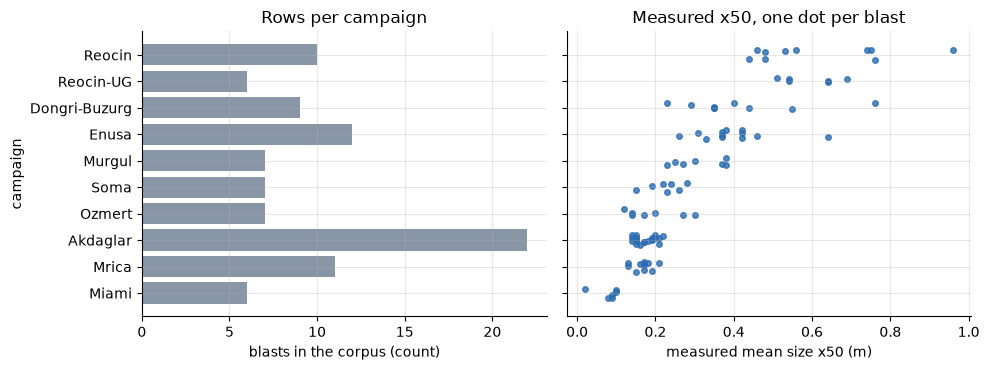

In [3]:
# Tabulate each campaign, ordered by its mean size, then draw its row count and every blast's measured size
sites = sorted({b.site for b in train}, key=lambda s: np.mean([b.x50_m for b in train if b.site == s]))
rows = []
for site in sites:
    sizes = np.array([b.x50_m for b in train if b.site == site])
    share = f"{len(sizes) / len(train):.0%}"
    rows.append((site, len(sizes), share, f"{sizes.mean():.3f}", f"{sizes.min():.2f}", f"{sizes.max():.2f}"))
header = ["campaign", "n", "share of rows", "mean x50 (m)", "min", "max"]
show_table(header, rows[::-1])
means = [float(r[3]) for r in rows]
print(f"largest campaign mean over the smallest: {max(means) / min(means):.1f}")

positions = np.arange(len(sites))
rng = np.random.default_rng(0)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
left.barh(positions, [r[1] for r in rows], color="#8896a5")
left.set_xlabel("blasts in the corpus (count)")
left.set_title("Rows per campaign")
for position, site in zip(positions, sites):
    sizes = [b.x50_m for b in train if b.site == site]
    right.scatter(sizes, position + rng.uniform(-0.2, 0.2, len(sizes)), s=16, color="#2b6cb0", alpha=0.8)
right.set_xlabel("measured mean size x50 (m)")
right.set_title("Measured x50, one dot per blast")
left.set_yticks(positions, sites)
left.set_ylabel("campaign")
fig.tight_layout()
plt.show()

The left panel shows the imbalance: Akdaglar alone supplies 22 of the 97 rows, 23 percent, while Miami and Reocin-UG supply 6 each. The right panel shows the separation: the campaign means run from 0.080 m at Miami to 0.616 m at Reocin, a ratio of 7.7, and the dots of Akdaglar, Mrica and Miami sit in narrow bands far to the left of Reocin and Reocin-UG. Dongri-Buzurg and Enusa spread widely, so campaigns also differ in how much their own blasts vary. The figure does not say why the campaigns differ (rock, design or explosive), and it does not say that the sizes can be predicted from the inputs; it says that a prediction for a new campaign cannot lean on rows of that campaign.

### Step 3: the inputs by campaign and the declared envelope

The engine declares a training envelope, the range of each of the seven inputs on the corpus (`TRAINING_ENVELOPE`), and refuses or stamps a prediction outside it; `envelope_report` counts the rows outside. Two further numbers say how the campaigns relate to each input: in how many campaigns the input takes a single value, and the share of its variance that lies between campaigns, computed as one minus the within-campaign sum of squares over the total sum of squares (the eta-squared of a one-way analysis of variance). A share near 100 percent means the campaign nearly fixes the input; a share near 0 means the campaigns are interchangeable on it. The measured size `x50_m` is added as a last row for reference.

In [4]:
# For each input: the declared range, the rows outside it, the campaigns with one value and the between-campaign share
report = bf.envelope_report(train)
rows = []
for name in (*bf.FEATURES, "x50_m"):
    by_site = {s: np.array([getattr(b, name) for b in train if b.site == s]) for s in sites}
    values = np.array([getattr(b, name) for b in train])
    within = sum(((v - v.mean()) ** 2).sum() for v in by_site.values())
    between = 1 - within / ((values - values.mean()) ** 2).sum()
    single = sum(len(set(v)) == 1 for v in by_site.values())
    low, high = bf.TRAINING_ENVELOPE.get(name, (values.min(), values.max()))
    outside = report[name]["n_outside_envelope"] if name in report else "-"
    rows.append((name, f"{low:g} to {high:g}", outside, f"{single} of {len(sites)}", f"{between:.0%}"))
header = ["input", "declared range", "rows outside",
          "campaigns with one value", "variance between campaigns"]
show_table(header, rows)

| input | declared range | rows outside | campaigns with one value | variance between campaigns |
|:---|---:|---:|---:|---:|
| S_over_B | 1 to 1.75 | 0 | 4 of 10 | 57% |
| H_over_B | 1.33 to 6.82 | 0 | 2 of 10 | 85% |
| B_over_D | 17.98 to 39.47 | 0 | 3 of 10 | 70% |
| T_over_B | 0.5 to 4.67 | 0 | 1 of 10 | 84% |
| Pf_kg_m3 | 0.22 to 1.26 | 0 | 1 of 10 | 63% |
| XB_m | 0.02 to 2.35 | 0 | 1 of 10 | 53% |
| E_GPa | 9.57 to 60 | 0 | 10 of 10 | 100% |
| x50_m | 0.02 to 0.96 | - | 0 of 10 | 80% |

Every input lies inside the envelope, which is not a finding: the envelope is the corpus's own range, so zero rows outside is true by construction (the last row, the measured size, has no declared envelope and shows the corpus range). The informative columns are the last two. The rock modulus E takes a single value in each of the ten campaigns, so all of its variance lies between campaigns: E is a campaign label written as a number. The bench-height and stemming ratios follow, with 85 and 84 percent of their variance between campaigns, and even the least campaign-bound input, the in situ block size, has 53 percent. The measured size sits at 80 percent. The table does not say which inputs matter for fragmentation, only how tightly each one is tied to its campaign.

The next cell draws the same seven inputs, one panel each, with a row of dots per campaign, the declared envelope as a shaded band and the five field blasts of the validation set as red dots on the top row.

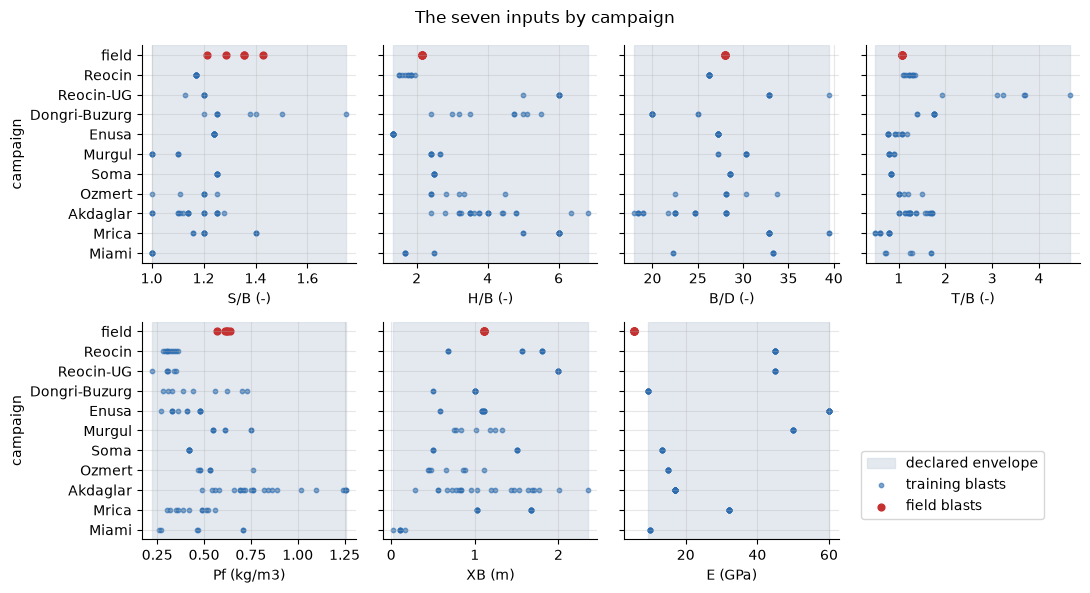

In [5]:
# One panel per input: every campaign's blasts, the declared envelope as a band and the field blasts in red
field = bf.load_field_holdout()
units = {"S_over_B": "S/B (-)", "H_over_B": "H/B (-)", "B_over_D": "B/D (-)", "T_over_B": "T/B (-)",
         "Pf_kg_m3": "Pf (kg/m3)", "XB_m": "XB (m)", "E_GPa": "E (GPa)"}
fig, axes = plt.subplots(2, 4, figsize=(11, 6), sharey=True)
for ax, name in zip(axes.flat, bf.FEATURES):
    low, high = bf.TRAINING_ENVELOPE[name]
    ax.axvspan(low, high, color="#cbd5e0", alpha=0.5, label="declared envelope")
    for position, site in enumerate(sites):
        values = [getattr(b, name) for b in train if b.site == site]
        label = "training blasts" if position == 0 else None
        ax.scatter(values, [position] * len(values), s=10, color="#2b6cb0", alpha=0.6, label=label)
    extra = [getattr(b, name) for b in field]
    ax.scatter(extra, [len(sites)] * len(extra), s=24, color="#c53030", label="field blasts")
    ax.set_xlabel(units[name])
axes[0, 0].set_yticks(range(len(sites) + 1), [*sites, "field"])
axes[0, 0].set_ylabel("campaign")
axes[1, 0].set_ylabel("campaign")
axes[1, 3].axis("off")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower right", bbox_to_anchor=(0.96, 0.12))
fig.suptitle("The seven inputs by campaign")
fig.tight_layout()
plt.show()

Each row of dots is one campaign and the shaded band is the declared envelope. The modulus panel shows the structure at a glance: ten vertical stacks, one per campaign, with nothing in between. The red dots show the extrapolation case: the five field blasts all have E = 5.6 GPa, to the left of the band and below the training minimum, while their other six inputs sit inside it. Only the modulus makes them an extrapolation. What the figure cannot show is the joint structure: a blast can sit inside the band on every input and still be an unusual combination, and a band that is the corpus's own range says nothing about how densely it was sampled.

### Step 4: the validation sets

Besides the 97 training rows the engine ships three more sets: the 13 blasts of the 2010 paper's validation, the 12 of the 2012 paper's, and the five field blasts. The cell loads them with `load_holdout` and `load_field_holdout` and tabulates, for each set, its size, its modulus range, how many of its sites are also training campaigns and how many of its rows are also training rows. A validation row that is also a training row inflates any score, so the count matters before any score exists.

In [6]:
# The two published validation sets and the field set: size, modulus range, shared sites and shared rows
training_sites = {b.site for b in train}
sets = {"2010": bf.load_holdout(protocol="2010"), "2012": bf.load_holdout(protocol="2012"), "field": field}
rows = []
for name, blasts in sets.items():
    modulus = [b.E_GPa for b in blasts]
    shared_sites = len({b.site for b in blasts} & training_sites)
    shared_rows = sum(bool(b.meta.get("in_training_table")) for b in blasts)
    rows.append((name, len(blasts), f"{min(modulus):.2f} to {max(modulus):.2f}", shared_sites, shared_rows))
header = ["set", "blasts", "E (GPa)", "sites also in training",
          "rows also in training"]
show_table(header, rows)
print("lowest training modulus (GPa):", min(b.E_GPa for b in train))

| set | blasts | E (GPa) | sites also in training | rows also in training |
|:---|---:|---:|---:|---:|
| 2010 | 13 | 9.57 to 60.00 | 9 | 0 |
| 2012 | 12 | 9.57 to 60.00 | 9 | 1 |
| field | 5 | 5.60 to 5.60 | 0 | 0 |

lowest training modulus (GPa): 9.57


The two published validation sets span the same modulus range as the training table, 9.57 to 60 GPa, so they validate inside the envelope, and nine of their sites are training campaigns: a published validation of 12 or 13 blasts tests a model at mines it has already seen. One of the 12 blasts of 2012 is a training row, a leak that later notebooks keep visible. The field set has a single modulus, 5.60 GPa, against a training minimum of 9.57, and none of its sites is a training campaign: it is the product's deliberate extrapolation case. The table does not show how hard any set is, only where it sits relative to the training rows; the cost of that overlap is the subject of topic 04.

### Step 5: the sixteen cases

The product does not predict for 97 blasts at once; it organises them into cases, each a coherent set that answers one question: the real campaigns, the field set as an extrapolation control, three synthetic design cases and two controls. The cell runs the product's own registry (`list_cases`) and its loader (`blasts_for_case`) from `data-pipeline/`, counts the blasts each case carries and asks the engine, with `has_absolute_geometry`, how many of them have a known scale in metres. Look for the case that has none.

In [7]:
# Run the product's case registry: every case, the blasts it carries and how many have a known scale
from pipeline.model.blasts import blasts_for_case
from pipeline.registry import category_label, list_cases

rows = []
for case in list_cases():
    blasts = blasts_for_case(case)
    scaled = sum(bf.has_absolute_geometry(b) for b in blasts)
    rows.append((case.id, category_label(case.category)[0], len(blasts), scaled))
header = ["case", "category", "blasts", "with a known scale"]
show_table(header, rows, left=2)
print("cases:", len(rows))

| case | category | blasts | with a known scale |
|:---|:---|---:|---:|
| real-enusa | Real campaigns | 12 | 12 |
| real-reocin | Real campaigns | 10 | 10 |
| real-reocin-ug | Real campaigns | 6 | 6 |
| real-murgul | Real campaigns | 7 | 7 |
| real-mrica | Real campaigns | 11 | 11 |
| real-soma | Real campaigns | 7 | 7 |
| real-dongri-buzurg | Real campaigns | 9 | 9 |
| real-akdaglar | Real campaigns | 22 | 22 |
| real-ozmert | Real campaigns | 7 | 7 |
| real-miami | Negative controls | 6 | 0 |
| real-granite-ne | Extrapolation control | 5 | 5 |
| synth-sweep-burden | Parameter sweeps | 12 | 12 |
| synth-sweep-powder | Parameter sweeps | 12 | 12 |
| synth-ibsd-capped | Structural control | 12 | 12 |
| ctrl-degenerate | Negative controls | 6 | 6 |
| ctrl-oracle | Positive control | 8 | 8 |

cases: 16


Nine real-campaign cases carry 91 of the 97 corpus blasts, and every one of their blasts has a known scale. The tenth campaign, Miami, is the case with none: 0 of its 6 blasts, because the source publishes no hole diameter and no length, so the engine cannot turn its ratios into metres and every arm that needs a volume must abstain there. The synthetic cases are designs fired on paper, with a hole diameter this product chose, and the two controls exist to test the harness: a set of designs that are not blasts, and an oracle. The table lists what exists; it says nothing yet about how any case scores, which starts in topic 04.

### Reproduction check: the registry and the committed index

The offline bake wrote `data/derived/manifests/index.json`, the list of cases the web workbench shows, from the same registry the previous cell ran, so the two must name the same cases. This is the notebook's only reproduction check; the parity of the numbers inside each artifact belongs to the product's tests.

In [8]:
# The registry's case ids against the index the offline bake committed
index = json.loads((DERIVED / "manifests" / "index.json").read_text(encoding="utf-8"))
committed_ids = sorted(case["case_id"] for case in index["cases"])
print("same case ids in both:", committed_ids == sorted(case.id for case in list_cases()))
print("cases in the committed index:", len(committed_ids))

same case ids in both: True
cases in the committed index: 16


The registry and the committed index name the same 16 cases, so what the web workbench shows is what this notebook just ran. The check confirms that the two lists agree; it says nothing about the numbers inside any case.

## Results

**Answer:** The corpus holds 97 blasts from ten campaigns, and the campaigns are very unequal. They differ in size, from 22 rows at Akdaglar to 6 at Miami and at Reocin-UG; in outcome, with campaign mean sizes from 0.080 m to 0.616 m, a ratio of 7.7; and in kind, since 80 percent of the variance of the measured size and 100 percent of the variance of the rock modulus lie between campaigns rather than inside them.

**What follows.** A random split of these rows would put blasts of one campaign on both sides of the split, and a model could then score well by recognising the campaign through its modulus instead of by learning fragmentation. That is why the product holds out whole campaigns (topic 04), why the five field blasts at 5.60 GPa are kept as an extrapolation case, and why the one campaign without a known scale, Miami, must be refused by every predictor that needs a volume.

**What this notebook does not show.** It predicts nothing and scores nothing. The envelope check is true by construction, because the envelope is the corpus's own range. The between-campaign share says how tightly an input is tied to its campaign, not how much it matters for fragmentation. And whether the shipped rows match the source paper is the question of notebook 03 of this topic.

## Summary

- `load_training_corpus()` returns 97 records of seven inputs and a measured size, and checks them against the paper while loading.
- The ten campaigns are unequal in rows (22 down to 6) and in mean size (0.080 to 0.616 m), and the modulus E takes one value per campaign.
- Every input lies inside the declared envelope because the envelope is the corpus range; the five field blasts at 5.60 GPa fall outside it.
- The product's registry holds 16 cases, and the Miami campaign is the one with no known scale in metres.
- Next: notebook 02 turns the ratios into metres, which the classical equation needs.

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the 97-blast corpus and the first validation set)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the second validation set)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/